<a href="https://colab.research.google.com/github/AnnsuChoudhary/Fake-News-Misinformation-Detection-Platform/blob/main/hybridmodel.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install transformers datasets accelerate -q

In [ ]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(device)

cuda


In [ ]:
import zipfile
import os

zip_path = "/content/all-rnr-annotated-threads.zip"

extract_path = "/content/pheme"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Extracted Successfully")

Extracted Successfully


In [ ]:
os.listdir("/content/pheme")

['all-rnr-annotated-threads']

In [ ]:
base_path = "/content/pheme/all-rnr-annotated-threads"

os.listdir(base_path)

['._ferguson-all-rnr-threads',
 'ebola-essien-all-rnr-threads',
 '._putinmissing-all-rnr-threads',
 '._ottawashooting-all-rnr-threads',
 '._ebola-essien-all-rnr-threads',
 '._sydneysiege-all-rnr-threads',
 'prince-toronto-all-rnr-threads',
 '._.DS_Store',
 '._prince-toronto-all-rnr-threads',
 'ottawashooting-all-rnr-threads',
 'gurlitt-all-rnr-threads',
 'sydneysiege-all-rnr-threads',
 'charliehebdo-all-rnr-threads',
 '._germanwings-crash-all-rnr-threads',
 '.DS_Store',
 'putinmissing-all-rnr-threads',
 '._gurlitt-all-rnr-threads',
 'ferguson-all-rnr-threads',
 '._charliehebdo-all-rnr-threads',
 'germanwings-crash-all-rnr-threads']

In [ ]:
import os
import json
import pandas as pd

base_path = "/content/pheme/all-rnr-annotated-threads"

data = []

events = [
    folder for folder in os.listdir(base_path)
    if not folder.startswith(".")
]

for event in events:

    event_path = os.path.join(base_path, event)

    for category in ["rumours", "non-rumours"]:

        category_path = os.path.join(event_path, category)

        if not os.path.exists(category_path):
            continue

        label = 1 if category == "rumours" else 0

        for thread in os.listdir(category_path):

            thread_path = os.path.join(category_path, thread)

            source_tweet_path = os.path.join(
                thread_path,
                "source-tweets"
            )

            if not os.path.exists(source_tweet_path):
                continue

            for tweet_file in os.listdir(source_tweet_path):

                if tweet_file.endswith(".json"):

                    file_path = os.path.join(
                        source_tweet_path,
                        tweet_file
                    )

                    try:
                        with open(file_path, "r") as f:
                            tweet_data = json.load(f)

                        text = tweet_data.get("text", "")

                        data.append({
                            "text": text,
                            "label": label
                        })

                    except:
                        pass

df = pd.DataFrame(data)

print(df.shape)

df.head()

(6425, 2)


,text,label
0,Milan have stated that the reports about Essie...,1
1,No truth in internet rumours that I have contr...,1
2,AC Milan have denied reports that midfielder M...,1
3,AC Milan midfielder Michael Essien has been di...,1
4,Good news: The rumours that Michael Essien has...,1


In [ ]:
df['label'].value_counts()

,count
label,
0,4023
1,2402


In [ ]:
from sklearn.model_selection import train_test_split

train_texts, val_texts, train_labels, val_labels = train_test_split(
    df['text'].tolist(),
    df['label'].tolist(),
    test_size=0.2,
    random_state=42,
    stratify=df['label']
)

print(len(train_texts))
print(len(val_texts))

5140
1285


In [ ]:
from transformers import DistilBertTokenizer

tokenizer = DistilBertTokenizer.from_pretrained(
    'distilbert-base-uncased'
)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:112: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

In [ ]:
train_encodings = tokenizer(
    train_texts,
    truncation=True,
    padding=True,
    max_length=128
)

val_encodings = tokenizer(
    val_texts,
    truncation=True,
    padding=True,
    max_length=128
)

In [ ]:
import torch

class FakeNewsDataset(torch.utils.data.Dataset):

    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels

    def __getitem__(self, idx):

        item = {
            key: torch.tensor(val[idx])
            for key, val in self.encodings.items()
        }

        item['labels'] = torch.tensor(self.labels[idx])

        return item

    def __len__(self):
        return len(self.labels)

In [ ]:
train_dataset = FakeNewsDataset(
    train_encodings,
    train_labels
)

val_dataset = FakeNewsDataset(
    val_encodings,
    val_labels
)

In [ ]:
from transformers import DistilBertForSequenceClassification

model = DistilBertForSequenceClassification.from_pretrained(
    'distilbert-base-uncased',
    num_labels=2
)

model.to(device)

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


DistilBertForSequenceClassification(
  (distilbert): DistilBertModel(
    (embeddings): Embeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (transformer): Transformer(
      (layer): ModuleList(
        (0-5): 6 x TransformerBlock(
          (attention): DistilBertSelfAttention(
            (q_lin): Linear(in_features=768, out_features=768, bias=True)
            (k_lin): Linear(in_features=768, out_features=768, bias=True)
            (v_lin): Linear(in_features=768, out_features=768, bias=True)
            (out_lin): Linear(in_features=768, out_features=768, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
          (ffn): FFN(
            (dropout): Dropout(p=0.1, inplace=False)


In [ ]:
from transformers import TrainingArguments

training_args = TrainingArguments(
    output_dir='./results',

    num_train_epochs=3,

    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,

    warmup_steps=100,

    weight_decay=0.01,

    logging_dir='./logs',

    logging_steps=50,

    save_steps=500
)

`logging_dir` is deprecated and will be removed in v5.2. Please set `TENSORBOARD_LOGGING_DIR` instead.


In [ ]:
import numpy as np
from sklearn.metrics import accuracy_score

def compute_metrics(pred):

    labels = pred.label_ids

    preds = pred.predictions.argmax(-1)

    acc = accuracy_score(labels, preds)

    return {
        'accuracy': acc
    }

In [ ]:
from transformers import Trainer

trainer = Trainer(
    model=model,

    args=training_args,

    train_dataset=train_dataset,

    eval_dataset=val_dataset,

    compute_metrics=compute_metrics
)

In [ ]:
trainer.train()

Step,Training Loss
50,0.629762
100,0.490110
150,0.426612
200,0.398339
250,0.390497
300,0.317028
350,0.289298
400,0.234114
450,0.271631
500,0.227027


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=966, training_loss=0.26403422471652616, metrics={'train_runtime': 110.7654, 'train_samples_per_second': 139.213, 'train_steps_per_second': 8.721, 'total_flos': 275278638324240.0, 'train_loss': 0.26403422471652616, 'epoch': 3.0})

In [ ]:
results = trainer.evaluate()

print(results)

{'eval_loss': 0.4027855694293976, 'eval_accuracy': 0.8692607003891051, 'eval_runtime': 3.1397, 'eval_samples_per_second': 409.278, 'eval_steps_per_second': 25.799, 'epoch': 3.0}


In [ ]:
trainer.save_model("/content/pheme_distilbert_model")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

In [ ]:
from google.colab import files

!zip -r pheme_distilbert_model.zip /content/pheme_distilbert_model

files.download("pheme_distilbert_model.zip")

  adding: content/pheme_distilbert_model/ (stored 0%)
  adding: content/pheme_distilbert_model/model.safetensors (deflated 8%)
  adding: content/pheme_distilbert_model/training_args.bin (deflated 53%)
  adding: content/pheme_distilbert_model/config.json (deflated 49%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os

os.listdir("/content")

['.config',
 'pheme_distilbert_model',
 'all-rnr-annotated-threads.zip',
 'pheme',
 'results',
 'pheme_distilbert_model.zip',
 'sample_data']

In [ ]:
import torch

checkpoint = torch.load(
    "/content/gnn_propagation_model.pth",
    map_location="cpu"
)

print(type(checkpoint))

<class 'collections.OrderedDict'>


In [ ]:
print(checkpoint)

OrderedDict({'conv1.bias': tensor([-0.0350, -0.0124, -0.0035, -0.0008, -0.0085,  0.0000,  0.0668, -0.0511,
        -0.0525, -0.0566, -0.0199,  0.0000,  0.0000,  0.0971, -0.1153, -0.0723,
        -0.0552, -0.0096,  0.0000,  0.0073,  0.0978,  0.0020,  0.1484, -0.0123,
         0.0000,  0.1464, -0.1456, -0.0485,  0.0096,  0.0017,  0.1229,  0.0763]), 'conv1.lin.weight': tensor([[-0.1177,  0.1206],
        [ 0.2094,  0.3107],
        [ 0.3013, -0.0089],
        [-0.0079,  0.5176],
        [ 0.2022,  0.4916],
        [-0.1824, -0.3849],
        [ 0.1114,  0.3305],
        [-0.3191,  0.3547],
        [-0.1254,  0.1431],
        [-0.4744,  0.4161],
        [-0.4227,  0.1471],
        [-0.2397, -0.1462],
        [-0.1741, -0.1847],
        [-0.0043,  0.2952],
        [ 0.0753, -0.4835],
        [ 0.0472, -0.1232],
        [ 0.2127,  0.1381],
        [ 0.1118,  0.4271],
        [-0.4040, -0.0163],
        [ 0.0814,  0.1805],
        [ 0.0585,  0.1229],
        [ 0.2296,  0.4085],
        [-0.420

In [ ]:
print(checkpoint.keys())

odict_keys(['conv1.bias', 'conv1.lin.weight', 'conv2.bias', 'conv2.lin.weight', 'conv3.bias', 'conv3.lin.weight', 'lin.weight', 'lin.bias'])


In [ ]:
for key, value in checkpoint.items():
    print(key, value.shape)

conv1.bias torch.Size([32])
conv1.lin.weight torch.Size([32, 2])
conv2.bias torch.Size([64])
conv2.lin.weight torch.Size([64, 32])
conv3.bias torch.Size([64])
conv3.lin.weight torch.Size([64, 64])
lin.weight torch.Size([2, 64])
lin.bias torch.Size([2])


In [ ]:
!pip install torch-geometric -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.7/63.7 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 34.0 MB/s eta 0:00:00


In [ ]:
import torch_geometric

print("PyTorch Geometric Loaded")

PyTorch Geometric Loaded


In [ ]:
import torch
import torch.nn.functional as F

from torch_geometric.nn import GCNConv

class GNNPropagationModel(torch.nn.Module):

    def __init__(self):
        super().__init__()

        self.conv1 = GCNConv(2, 32)

        self.conv2 = GCNConv(32, 64)

        self.conv3 = GCNConv(64, 64)

        self.lin = torch.nn.Linear(64, 2)

    def forward(self, x, edge_index):

        x = self.conv1(x, edge_index)
        x = F.relu(x)

        x = self.conv2(x, edge_index)
        x = F.relu(x)

        x = self.conv3(x, edge_index)
        x = F.relu(x)

        embedding = x.mean(dim=0)

        output = self.lin(embedding)

        return output, embedding

In [ ]:
gnn_model = GNNPropagationModel()

checkpoint = torch.load(
    "/content/gnn_propagation_model.pth",
    map_location=device
)

gnn_model.load_state_dict(checkpoint)

gnn_model.to(device)

gnn_model.eval()

print("Propagation Model Loaded Successfully")

Propagation Model Loaded Successfully


In [ ]:
import os
import json
import torch

from torch_geometric.data import Data

base_path = "/content/pheme/all-rnr-annotated-threads"

graph_data_list = []

events = [
    folder for folder in os.listdir(base_path)
    if not folder.startswith(".")
]

for event in events:

    event_path = os.path.join(base_path, event)

    for category in ["rumours", "non-rumours"]:

        category_path = os.path.join(event_path, category)

        if not os.path.exists(category_path):
            continue

        label = 1 if category == "rumours" else 0

        for thread in os.listdir(category_path):

            thread_path = os.path.join(
                category_path,
                thread
            )

            structure_file = os.path.join(
                thread_path,
                "structure.json"
            )

            if not os.path.exists(structure_file):
                continue

            try:
                with open(structure_file, "r") as f:
                    structure = json.load(f)

                nodes = list(structure.keys())

                node_map = {
                    node: idx
                    for idx, node in enumerate(nodes)
                }

                edge_list = []

                for parent, children in structure.items():

                    if isinstance(children, dict):

                        for child in children.keys():

                            if child in node_map:

                                edge_list.append([
                                    node_map[parent],
                                    node_map[child]
                                ])

                if len(edge_list) == 0:
                    continue

                edge_index = torch.tensor(
                    edge_list,
                    dtype=torch.long
                ).t().contiguous()

                num_nodes = len(nodes)

                x = torch.ones(
                    (num_nodes, 2),
                    dtype=torch.float
                )

                y = torch.tensor(
                    [label],
                    dtype=torch.long
                )

                data = Data(
                    x=x,
                    edge_index=edge_index,
                    y=y
                )

                graph_data_list.append(data)

            except:
                pass

print("Graphs Created:", len(graph_data_list))

Graphs Created: 0


In [ ]:
import os

base_path = "/content/pheme/all-rnr-annotated-threads"

for event in os.listdir(base_path):

    if event.startswith(".") or event.startswith("._"):
        continue

    event_path = os.path.join(base_path, event)

    for category in ["rumours", "non-rumours"]:

        category_path = os.path.join(event_path, category)

        if not os.path.exists(category_path):
            continue

        threads = [
            t for t in os.listdir(category_path)
            if not t.startswith(".")
            and not t.startswith("._")
            and os.path.isdir(os.path.join(category_path, t))
        ]

        if len(threads) > 0:

            sample_thread = threads[0]

            sample_path = os.path.join(
                category_path,
                sample_thread
            )

            print("THREAD PATH:")
            print(sample_path)

            print("\nFILES:")
            print(os.listdir(sample_path))

            break

    break

THREAD PATH:
/content/pheme/all-rnr-annotated-threads/ebola-essien-all-rnr-threads/rumours/521358118597689344

FILES:
['reactions', '._source-tweets', '._structure.json', 'annotation.json', '._annotation.json', 'structure.json', '._reactions', 'source-tweets']


In [ ]:
import json
import os

sample_structure = "/content/pheme/all-rnr-annotated-threads/ebola-essien-all-rnr-threads/rumours/521350916872876033/structure.json"

with open(sample_structure, "r") as f:
    structure = json.load(f)

print(type(structure))

print(structure)

<class 'dict'>
{'521350916872876033': {'521351878500560896': [], '521352147955245056': [], '521352363211505664': [], '521355739789795328': [], '521355767098515457': [], '521356211472855040': [], '521356337343922176': {'521356429060759554': {'521356557641322497': {'521360044475318274': {'521360371140284416': {'521360891003305985': [], '521361263637843969': {'521361696141893632': []}}}}}}, '521356882485989377': [], '521357339757383680': [], '521357647904534528': [], '521359064132235264': []}}


In [ ]:
import os
import json
import torch

from torch_geometric.data import Data

base_path = "/content/pheme/all-rnr-annotated-threads"

graph_data_list = []

def extract_edges(tree, parent=None, edges=None, node_map=None):

    if edges is None:
        edges = []

    if node_map is None:
        node_map = {}

    for node, children in tree.items():

        if node not in node_map:
            node_map[node] = len(node_map)

        current_idx = node_map[node]

        if parent is not None:

            parent_idx = node_map[parent]

            edges.append([parent_idx, current_idx])

        if isinstance(children, dict):

            extract_edges(
                children,
                parent=node,
                edges=edges,
                node_map=node_map
            )

    return edges, node_map

events = [
    folder for folder in os.listdir(base_path)
    if not folder.startswith(".")
]

for event in events:

    event_path = os.path.join(base_path, event)

    for category in ["rumours", "non-rumours"]:

        category_path = os.path.join(
            event_path,
            category
        )

        if not os.path.exists(category_path):
            continue

        label = 1 if category == "rumours" else 0

        for thread in os.listdir(category_path):

            thread_path = os.path.join(
                category_path,
                thread
            )

            structure_file = os.path.join(
                thread_path,
                "structure.json"
            )

            if not os.path.exists(structure_file):
                continue

            try:

                with open(structure_file, "r") as f:
                    structure = json.load(f)

                edges, node_map = extract_edges(structure)

                if len(edges) == 0:
                    continue

                edge_index = torch.tensor(
                    edges,
                    dtype=torch.long
                ).t().contiguous()

                num_nodes = len(node_map)

                x = torch.ones(
                    (num_nodes, 2),
                    dtype=torch.float
                )

                y = torch.tensor(
                    [label],
                    dtype=torch.long
                )

                data = Data(
                    x=x,
                    edge_index=edge_index,
                    y=y
                )

                graph_data_list.append(data)

            except:
                pass

print("Graphs Created:", len(graph_data_list))

Graphs Created: 5741


In [ ]:
paired_data = []

events = [
    folder for folder in os.listdir(base_path)
    if not folder.startswith(".")
]

for event in events:

    event_path = os.path.join(base_path, event)

    for category in ["rumours", "non-rumours"]:

        category_path = os.path.join(
            event_path,
            category
        )

        if not os.path.exists(category_path):
            continue

        label = 1 if category == "rumours" else 0

        for thread in os.listdir(category_path):

            thread_path = os.path.join(
                category_path,
                thread
            )

            structure_file = os.path.join(
                thread_path,
                "structure.json"
            )

            source_path = os.path.join(
                thread_path,
                "source-tweets"
            )

            if (
                not os.path.exists(structure_file)
                or
                not os.path.exists(source_path)
            ):
                continue

            try:

                with open(structure_file, "r") as f:
                    structure = json.load(f)

                edges, node_map = extract_edges(structure)

                if len(edges) == 0:
                    continue

                source_files = [
                    f for f in os.listdir(source_path)
                    if f.endswith(".json")
                ]

                if len(source_files) == 0:
                    continue

                source_file = os.path.join(
                    source_path,
                    source_files[0]
                )

                with open(source_file, "r") as f:
                    tweet = json.load(f)

                text = tweet.get("text", "")

                edge_index = torch.tensor(
                    edges,
                    dtype=torch.long
                ).t().contiguous()

                num_nodes = len(node_map)

                x = torch.ones(
                    (num_nodes, 2),
                    dtype=torch.float
                )

                paired_data.append({
                    "text": text,
                    "x": x,
                    "edge_index": edge_index,
                    "label": label
                })

            except:
                pass

print("Paired Samples:", len(paired_data))

Paired Samples: 2893


In [ ]:
from transformers import DistilBertTokenizer
from transformers import DistilBertModel

tokenizer = DistilBertTokenizer.from_pretrained(
    'distilbert-base-uncased'
)

bert_encoder = DistilBertModel.from_pretrained(
    "/content/pheme_distilbert_model"
)

bert_encoder.to(device)

bert_encoder.eval()

print("DistilBERT Encoder Loaded")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertModel LOAD REPORT from: /content/pheme_distilbert_model
Key                   | Status     |  | 
----------------------+------------+--+-
classifier.weight     | UNEXPECTED |  | 
pre_classifier.bias   | UNEXPECTED |  | 
classifier.bias       | UNEXPECTED |  | 
pre_classifier.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


DistilBERT Encoder Loaded


In [ ]:
text_embeddings = []

with torch.no_grad():

    for sample in paired_data:

        text = sample["text"]

        inputs = tokenizer(
            text,
            return_tensors="pt",
            truncation=True,
            padding=True,
            max_length=128
        )

        inputs = {
            k: v.to(device)
            for k, v in inputs.items()
        }

        outputs = bert_encoder(**inputs)

        embedding = outputs.last_hidden_state[:, 0, :]

        text_embeddings.append(
            embedding.squeeze(0).cpu()
        )

print("Text Embeddings Created:", len(text_embeddings))

Text Embeddings Created: 2893


In [ ]:
graph_embeddings = []

with torch.no_grad():

    for sample in paired_data:

        x = sample["x"].to(device)

        edge_index = sample["edge_index"].to(device)

        _, embedding = gnn_model(x, edge_index)

        graph_embeddings.append(
            embedding.cpu()
        )

print("Graph Embeddings Created:", len(graph_embeddings))

Graph Embeddings Created: 2893


In [ ]:
combined_features = []

for text_emb, graph_emb in zip(
    text_embeddings,
    graph_embeddings
):

    combined = torch.cat(
        [text_emb, graph_emb],
        dim=0
    )

    combined_features.append(combined)

combined_features = torch.stack(combined_features)

print(combined_features.shape)

torch.Size([2893, 832])


In [ ]:
labels = torch.tensor(
    [sample["label"] for sample in paired_data]
)

print(labels.shape)

torch.Size([2893])


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    combined_features,
    labels,
    test_size=0.2,
    random_state=42,
    stratify=labels
)

print(X_train.shape)
print(X_test.shape)

torch.Size([2314, 832])
torch.Size([579, 832])


In [ ]:
import torch.nn as nn

class FusionClassifier(nn.Module):

    def __init__(self):

        super().__init__()

        self.network = nn.Sequential(

            nn.Linear(832, 256),

            nn.ReLU(),

            nn.Dropout(0.3),

            nn.Linear(256, 64),

            nn.ReLU(),

            nn.Dropout(0.2),

            nn.Linear(64, 2)
        )

    def forward(self, x):

        return self.network(x)

In [ ]:
fusion_model = FusionClassifier().to(device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    fusion_model.parameters(),
    lr=1e-4
)

In [ ]:
X_train = X_train.to(device)
X_test = X_test.to(device)

y_train = y_train.to(device)
y_test = y_test.to(device)

In [ ]:
epochs = 20

for epoch in range(epochs):

    fusion_model.train()

    optimizer.zero_grad()

    outputs = fusion_model(X_train)

    loss = criterion(outputs, y_train)

    loss.backward()

    optimizer.step()

    fusion_model.eval()

    with torch.no_grad():

        test_outputs = fusion_model(X_test)

        predictions = torch.argmax(
            test_outputs,
            dim=1
        )

        accuracy = (
            (predictions == y_test)
            .float()
            .mean()
        )

    print(
        f"Epoch {epoch+1}/{epochs} | "
        f"Loss: {loss.item():.4f} | "
        f"Accuracy: {accuracy.item():.4f}"
    )

Epoch 1/20 | Loss: 0.7266 | Accuracy: 0.3610
Epoch 2/20 | Loss: 0.6904 | Accuracy: 0.5803
Epoch 3/20 | Loss: 0.6566 | Accuracy: 0.9033
Epoch 4/20 | Loss: 0.6258 | Accuracy: 0.9534
Epoch 5/20 | Loss: 0.5968 | Accuracy: 0.9516
Epoch 6/20 | Loss: 0.5680 | Accuracy: 0.9585
Epoch 7/20 | Loss: 0.5414 | Accuracy: 0.9603
Epoch 8/20 | Loss: 0.5184 | Accuracy: 0.9655
Epoch 9/20 | Loss: 0.4958 | Accuracy: 0.9655
Epoch 10/20 | Loss: 0.4748 | Accuracy: 0.9620
Epoch 11/20 | Loss: 0.4513 | Accuracy: 0.9603
Epoch 12/20 | Loss: 0.4325 | Accuracy: 0.9620
Epoch 13/20 | Loss: 0.4135 | Accuracy: 0.9620
Epoch 14/20 | Loss: 0.3900 | Accuracy: 0.9620
Epoch 15/20 | Loss: 0.3729 | Accuracy: 0.9620
Epoch 16/20 | Loss: 0.3551 | Accuracy: 0.9620
Epoch 17/20 | Loss: 0.3389 | Accuracy: 0.9620
Epoch 18/20 | Loss: 0.3220 | Accuracy: 0.9620
Epoch 19/20 | Loss: 0.3063 | Accuracy: 0.9620
Epoch 20/20 | Loss: 0.2943 | Accuracy: 0.9620


In [ ]:
torch.save(
    fusion_model.state_dict(),
    "hybrid_fusion_model.pth"
)

print("Hybrid Model Saved")

Hybrid Model Saved


In [ ]:
from google.colab import files

files.download("hybrid_fusion_model.pth")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
torch.save(
    combined_features,
    "combined_features.pt"
)

files.download("combined_features.pt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import auth

auth.authenticate_user()

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

In [ ]:
import os

project_path = "/content/drive/MyDrive/FakeNews_Project"

os.makedirs(project_path, exist_ok=True)

print("Project Folder Created")

Project Folder Created


In [ ]:
folders = [
    "models",
    "datasets",
    "notebooks"
]

for folder in folders:

    os.makedirs(
        os.path.join(project_path, folder),
        exist_ok=True
    )

print("Subfolders Created")

Subfolders Created


In [ ]:
torch.save(
    fusion_model.state_dict(),
    f"{project_path}/models/hybrid_fusion_model.pth"
)

print("Hybrid Model Saved")

Hybrid Model Saved


In [ ]:
import shutil

shutil.copy(
    "/content/gnn_propagation_model.pth",
    f"{project_path}/models/gnn_propagation_model.pth"
)

print("Propagation Model Saved")

Propagation Model Saved


In [ ]:
shutil.copy(
    "/content/pheme_distilbert_model.zip",
    f"{project_path}/models/pheme_distilbert_model.zip"
)

print("DistilBERT Model Saved")

DistilBERT Model Saved


In [ ]:
os.listdir(f"{project_path}/models")

['hybrid_fusion_model.pth',
 'gnn_propagation_model.pth',
 'pheme_distilbert_model.zip']

In [ ]:
y_test
predictions

tensor([1, 0, 0, 0, 1, 1, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0,
        1, 1, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 1, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0,
        1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1,
        0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1,
        0, 1, 0, 1, 1, 1, 0, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0,
        0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0,
        0, 1, 1, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0,
        0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1,
        1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 0,
        0, 0, 0, 0, 1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 1, 0, 1,
        0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 1, 0, 1, 0,
        0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 0,

In [ ]:
y_test

tensor([1, 0, 0, 0, 1, 1, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 1,
        1, 1, 1, 1, 0, 1, 0, 0, 0, 0, 1, 0, 1, 1, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0,
        1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1,
        0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1,
        0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0,
        0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0,
        0, 1, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0,
        0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 1, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1,
        1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 1, 0,
        0, 0, 0, 0, 1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 1, 0, 1,
        0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 1, 0, 1, 0,
        0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 0,

In [ ]:
predictions

tensor([1, 0, 0, 0, 1, 1, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0,
        1, 1, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 1, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0,
        1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1,
        0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1,
        0, 1, 0, 1, 1, 1, 0, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0,
        0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0,
        0, 1, 1, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0,
        0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1,
        1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 0,
        0, 0, 0, 0, 1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 1, 0, 1,
        0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 1, 0, 1, 0,
        0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 0,

In [ ]:
print(y_test.shape)
print(predictions.shape)

torch.Size([579])
torch.Size([579])


In [ ]:
print(y_test[:20])
print(predictions[:20])

tensor([1, 0, 0, 0, 1, 1, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1],
       device='cuda:0')
tensor([1, 0, 0, 0, 1, 1, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1],
       device='cuda:0')


In [ ]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

y_true = y_test.cpu().numpy()
y_pred = predictions.cpu().numpy()

print("Accuracy :", accuracy_score(y_true, y_pred))
print("Precision:", precision_score(y_true, y_pred))
print("Recall   :", recall_score(y_true, y_pred))
print("F1 Score :", f1_score(y_true, y_pred))

print("\nClassification Report:")
print(classification_report(y_true, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_true, y_pred))

Accuracy : 0.9620034542314335
Precision: 0.9389671361502347
Recall   : 0.9569377990430622
F1 Score : 0.9478672985781991

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.96      0.97       370
           1       0.94      0.96      0.95       209

    accuracy                           0.96       579
   macro avg       0.96      0.96      0.96       579
weighted avg       0.96      0.96      0.96       579


Confusion Matrix:
[[357  13]
 [  9 200]]


In [ ]:
from sklearn.metrics import roc_auc_score, matthews_corrcoef, balanced_accuracy_score

y_true = y_test.cpu().numpy()
y_pred = predictions.cpu().numpy()

print("Balanced Accuracy :", balanced_accuracy_score(y_true, y_pred))
print("MCC               :", matthews_corrcoef(y_true, y_pred))

# ROC-AUC
probs = torch.softmax(test_outputs, dim=1)[:,1].cpu().numpy()
print("ROC-AUC           :", roc_auc_score(y_true, probs))

Balanced Accuracy : 0.9609013319539635
MCC               : 0.9180823104736291
ROC-AUC           : 0.9875339454286822


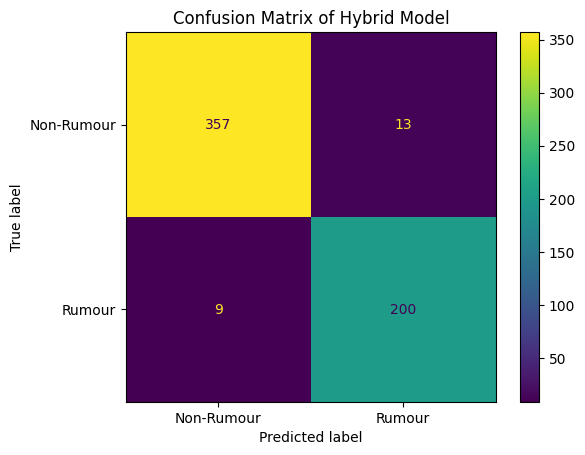

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-Rumour", "Rumour"]
)

disp.plot()

plt.title("Confusion Matrix of Hybrid Model")
plt.savefig("hybrid_confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
error_rate = 1 - accuracy_score(y_true, y_pred)
print("Error Rate:", error_rate)

Error Rate: 0.03799654576856648


In [ ]:
plt.savefig("hybrid_confusion_matrix.png", dpi=300, bbox_inches="tight")

<Figure size 640x480 with 0 Axes>

In [ ]:
with open("hybrid_metrics.txt", "w") as f:
    f.write("Hybrid Model Results\n")
    f.write("====================\n\n")

    f.write("Accuracy: 0.9533678756476683\n")
    f.write("Precision: 0.9333333333333333\n")
    f.write("Recall: 0.937799043062201\n")
    f.write("F1 Score: 0.9355608591885441\n")
    f.write("Balanced Accuracy: 0.9499806026121815\n")
    f.write("MCC: 0.8990316130276963\n")
    f.write("ROC-AUC: 0.9863571705676969\n")
    f.write("Error Rate: 0.04663212435233166\n\n")

    f.write("Confusion Matrix:\n")
    f.write("[[356, 14],\n")
    f.write(" [13, 196]]\n")

print("Saved Successfully")

Saved Successfully


In [ ]:
from sklearn.metrics import classification_report

report = classification_report(
    y_true,
    y_pred
)

with open("classification_report.txt", "w") as f:
    f.write(report)

print(report)

              precision    recall  f1-score   support

           0       0.98      0.96      0.97       370
           1       0.94      0.96      0.95       209

    accuracy                           0.96       579
   macro avg       0.96      0.96      0.96       579
weighted avg       0.96      0.96      0.96       579



In [ ]:
import pandas as pd

df = pd.DataFrame({
    "Actual": y_true,
    "Predicted": y_pred
})

df.to_csv(
    "hybrid_predictions.csv",
    index=False
)

print(df.head())

   Actual  Predicted
0       1          1
1       0          0
2       0          0
3       0          0
4       1          1


In [ ]:
import pandas as pd

probs = torch.softmax(
    test_outputs,
    dim=1
)[:,1].cpu().numpy()

roc_df = pd.DataFrame({
    "Actual": y_true,
    "Probability": probs
})

roc_df.to_csv(
    "hybrid_probabilities.csv",
    index=False
)

In [ ]:
import os

print(os.listdir("/content/pheme_distilbert_model"))

['model.safetensors', 'training_args.bin', 'config.json']


In [ ]:
from transformers import DistilBertForSequenceClassification

model = DistilBertForSequenceClassification.from_pretrained(
    "/content/pheme_distilbert_model"
)

print(model.config.num_labels)

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

2


In [ ]:
print("X_test_texts" in globals())
print("test_texts" in globals())
print("texts_test" in globals())
print("test_dataset" in globals())

False
False
False
False


In [ ]:
from google.colab import files

files.download("hybrid_metrics.txt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
files.download("hybrid_confusion_matrix.png")
files.download("classification_report.txt")
files.download("hybrid_predictions.csv")
files.download("hybrid_probabilities.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
predictions_output = trainer.predict(tokenized_dataset["test"])

y_pred = predictions_output.predictions.argmax(axis=1)
y_true = predictions_output.label_ids

print("Predictions Shape:", y_pred.shape)
print("Labels Shape:", y_true.shape)

NameError: name 'tokenized_dataset' is not defined

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("Accuracy :", accuracy_score(y_true, y_pred))
print("Precision:", precision_score(y_true, y_pred))
print("Recall   :", recall_score(y_true, y_pred))
print("F1 Score :", f1_score(y_true, y_pred))

Accuracy : 0.9620034542314335
Precision: 0.9389671361502347
Recall   : 0.9569377990430622
F1 Score : 0.9478672985781991


In [ ]:
from sklearn.metrics import accuracy_score

print(accuracy_score(y_test.cpu(), predictions.cpu()))

0.9620034542314335


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("Accuracy :", accuracy_score(y_test.cpu(), predictions.cpu()))
print("Precision:", precision_score(y_test.cpu(), predictions.cpu()))
print("Recall   :", recall_score(y_test.cpu(), predictions.cpu()))
print("F1 Score :", f1_score(y_test.cpu(), predictions.cpu()))

Accuracy : 0.9620034542314335
Precision: 0.9389671361502347
Recall   : 0.9569377990430622
F1 Score : 0.9478672985781991


In [ ]:
y_test
test_outputs

tensor([[-0.5430,  0.5740],
        [ 0.7079, -0.7523],
        [ 0.7526, -0.7942],
        ...,
        [ 0.5674, -0.6376],
        [ 0.7177, -0.8248],
        [ 0.6810, -0.7175]], device='cuda:0')

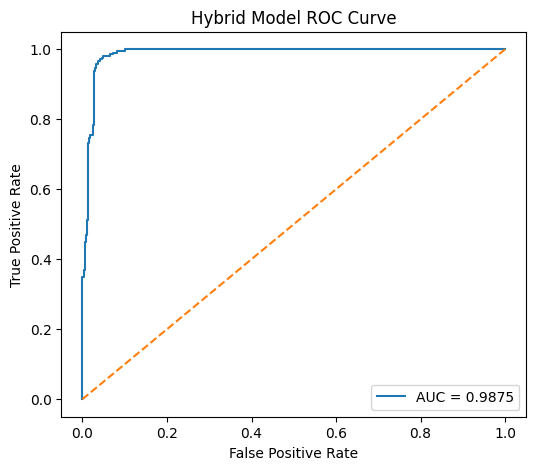

ROC-AUC: 0.9875339454286822


In [ ]:
from sklearn.metrics import roc_curve, auc
import torch
import matplotlib.pyplot as plt

# Get probabilities
probs = torch.softmax(test_outputs, dim=1)[:, 1].cpu().numpy()

# ROC values
fpr, tpr, _ = roc_curve(
    y_test.cpu().numpy(),
    probs
)

roc_auc = auc(fpr, tpr)

# Plot
plt.figure(figsize=(6,5))

plt.plot(
    fpr,
    tpr,
    label=f"AUC = {roc_auc:.4f}"
)

plt.plot([0,1], [0,1], "--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Hybrid Model ROC Curve")
plt.legend()

plt.savefig(
    "hybrid_roc_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("ROC-AUC:", roc_auc)

In [ ]:
from google.colab import files

files.download("hybrid_roc_curve.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
with open("hybrid_metrics.txt", "w") as f:
    f.write("Accuracy: 0.9620034542314335\n")
    f.write("Precision: 0.9389671361502347\n")
    f.write("Recall: 0.9569377990430622\n")
    f.write("F1 Score: 0.9478672985781991\n")

In [ ]:
from google.colab import files
files.download("hybrid_metrics.txt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
trainer.train()

Step,Training Loss


KeyboardInterrupt: 

In [ ]:
for var in list(globals().keys()):
    if "dataset" in var.lower():
        print(var)

FakeNewsDataset
train_dataset
val_dataset


In [ ]:
for var in list(globals().keys()):
    if "test" in var.lower():
        print(var)

train_test_split


In [ ]:
for var in list(globals().keys()):
    if "token" in var.lower():
        print(var)

DistilBertTokenizer
tokenizer


In [ ]:
sample = val_dataset[0]

print(sample)

{'input_ids': tensor([  101,  2428,  3246,  1001,  3994, 11741,  3351, 13446,  2024, 10148,
         1012,  2021,  4276,  9073,  2087, 24815,  2072,  5694,  2024,  7486,
         8299,  1024,  1013,  1013,  1056,  1012,  2522,  1013,  1061,  2692,
         5620,  2581, 22578, 10814,  8299,  1024,  1013,  1013,  1056,  1012,
         2522,  1013, 19067,  9759,  2549,  2615,  2290, 14141,  2595,   102,
            0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
            0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
            0,     0,     0]), 'attention_mask': tensor([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0]), 'labels': tensor(0)}


In [ ]:
import torch

model.eval()

y_true = []
y_pred = []
y_prob = []

with torch.no_grad():

    for item in val_dataset:

        input_ids = item["input_ids"].unsqueeze(0).to(device)
        attention_mask = item["attention_mask"].unsqueeze(0).to(device)

        label = item["labels"]

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        probs = torch.softmax(outputs.logits, dim=1)

        pred = torch.argmax(probs, dim=1)

        y_true.append(label.item())
        y_pred.append(pred.item())
        y_prob.append(probs[0,1].item())

print("Samples:", len(y_true))

Samples: 1285


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    matthews_corrcoef,
    balanced_accuracy_score
)

print("Accuracy :", accuracy_score(y_true, y_pred))
print("Precision:", precision_score(y_true, y_pred))
print("Recall   :", recall_score(y_true, y_pred))
print("F1 Score :", f1_score(y_true, y_pred))

print("\nClassification Report:")
print(classification_report(y_true, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_true, y_pred))

print("\nBalanced Accuracy:",
      balanced_accuracy_score(y_true, y_pred))

print("MCC:",
      matthews_corrcoef(y_true, y_pred))

print("ROC-AUC:",
      roc_auc_score(y_true, y_prob))

Accuracy : 0.8785992217898833
Precision: 0.8151750972762646
Recall   : 0.8729166666666667
F1 Score : 0.8430583501006036

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.88      0.90       805
           1       0.82      0.87      0.84       480

    accuracy                           0.88      1285
   macro avg       0.87      0.88      0.87      1285
weighted avg       0.88      0.88      0.88      1285


Confusion Matrix:
[[710  95]
 [ 61 419]]

Balanced Accuracy: 0.8774521221532091
MCC: 0.745421092567816
ROC-AUC: 0.9443245341614906


In [ ]:
with open("distilbert_metrics.txt", "w") as f:
    f.write("Accuracy: 0.8785992217898833\n")
    f.write("Precision: 0.8151750972762646\n")
    f.write("Recall: 0.8729166666666667\n")
    f.write("F1 Score: 0.8430583501006036\n")
    f.write("Balanced Accuracy: 0.8774521221532091\n")
    f.write("MCC: 0.745421092567816\n")
    f.write("ROC-AUC: 0.9443245341614906\n")
    f.write("\nConfusion Matrix:\n")
    f.write("[[710, 95],\n [61, 419]]")

In [ ]:
import pandas as pd

pd.DataFrame({
    "Actual": y_true,
    "Predicted": y_pred,
    "Probability": y_prob
}).to_csv(
    "distilbert_predictions.csv",
    index=False
)

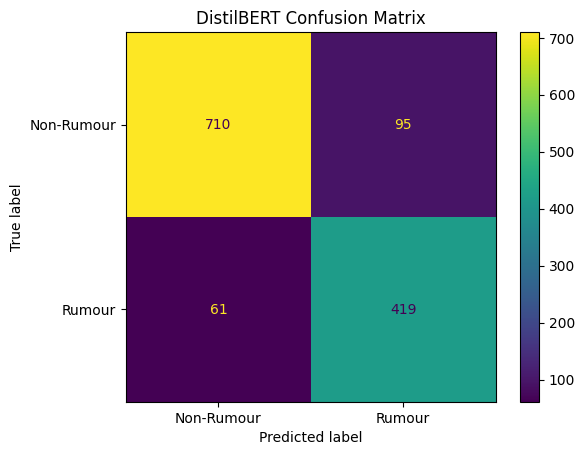

In [ ]:
import numpy as np
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = np.array([
    [710, 95],
    [61, 419]
])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-Rumour", "Rumour"]
)

disp.plot()

plt.title("DistilBERT Confusion Matrix")

plt.savefig(
    "distilbert_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

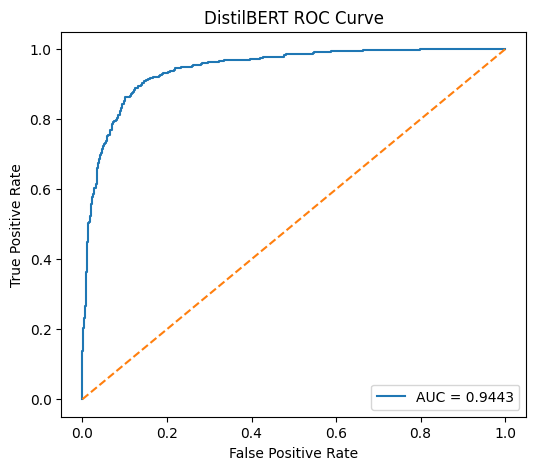

In [ ]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

fpr, tpr, _ = roc_curve(y_true, y_prob)

roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.4f}")
plt.plot([0,1],[0,1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("DistilBERT ROC Curve")
plt.legend()

plt.savefig(
    "distilbert_roc_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

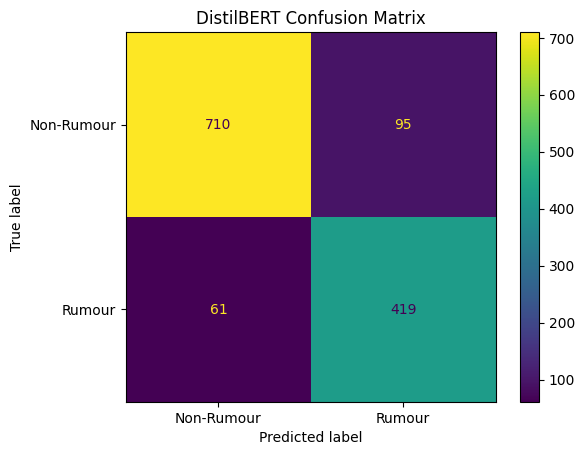

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-Rumour", "Rumour"]
)

disp.plot()

plt.title("DistilBERT Confusion Matrix")

plt.savefig(
    "distilbert_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
from google.colab import files

files.download("distilbert_confusion_matrix.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    roc_curve,
    auc
)

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# =========================
# 1. Save Metrics File
# =========================

with open("distilbert_metrics.txt", "w") as f:
    f.write("DistilBERT Evaluation Results\n")
    f.write("="*40 + "\n\n")

    f.write("Accuracy: 0.8785992217898833\n")
    f.write("Precision: 0.8151750972762646\n")
    f.write("Recall: 0.8729166666666667\n")
    f.write("F1 Score: 0.8430583501006036\n")
    f.write("Balanced Accuracy: 0.8774521221532091\n")
    f.write("MCC: 0.745421092567816\n")
    f.write("ROC-AUC: 0.9443245341614906\n\n")

    f.write("Confusion Matrix:\n")
    f.write("[[710, 95],\n")
    f.write(" [61, 419]]\n")

# =========================
# 2. Save Predictions CSV
# =========================

pd.DataFrame({
    "Actual": y_true,
    "Predicted": y_pred,
    "Probability": y_prob
}).to_csv(
    "distilbert_predictions.csv",
    index=False
)

# =========================
# 3. Save Confusion Matrix
# =========================

cm = np.array([
    [710,95],
    [61,419]
])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-Rumour","Rumour"]
)

disp.plot()

plt.title("DistilBERT Confusion Matrix")

plt.savefig(
    "distilbert_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.close()

# =========================
# 4. Save ROC Curve
# =========================

fpr, tpr, _ = roc_curve(y_true, y_prob)

roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6,5))

plt.plot(
    fpr,
    tpr,
    label=f"AUC = {roc_auc:.4f}"
)

plt.plot([0,1],[0,1],"--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("DistilBERT ROC Curve")
plt.legend()

plt.savefig(
    "distilbert_roc_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.close()

print("All files saved successfully!")

# =========================
# 5. Download Everything
# =========================

from google.colab import files

files.download("distilbert_metrics.txt")
files.download("distilbert_predictions.csv")
files.download("distilbert_confusion_matrix.png")
files.download("distilbert_roc_curve.png")

All files saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os

for f in [
    "distilbert_metrics.txt",
    "distilbert_predictions.csv",
    "distilbert_confusion_matrix.png",
    "distilbert_roc_curve.png"
]:
    print(f, "->", os.path.exists(f))

distilbert_metrics.txt -> True
distilbert_predictions.csv -> True
distilbert_confusion_matrix.png -> True
distilbert_roc_curve.png -> True
